# Orbitel Projet
**Prédiction du Churn Client – Régression Logistique & Prise de Décision Métier**

## Librairies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

print('Librairies chargées avec succès.')

Librairies chargées avec succès.


## Lecture des données

> **Note :** Modifiez uniquement la variable `DATA_DIR` pour pointer vers votre dossier de données.



In [12]:
# =====================================================================
# CHEMIN VERS LES DONNÉES – à modifier selon l'environnement (colab ou local)
# =====================================================================
DATA_DIR = 'C:\\PC ARMAND\\cours\\MBDIA\\ML DL\\'                      # Fichiers dans le même dossier que le notebook
# DATA_DIR = '/content/drive/MyDrive/'  # Google Colab + Drive

df_train = pd.read_csv(DATA_DIR + 'churn_train.csv')
df_test  = pd.read_csv(DATA_DIR + 'churn_test.csv')
df_new   = pd.read_csv(DATA_DIR + 'churn_new.csv')

print(f'Train : {df_train.shape}  |  Test : {df_test.shape}  |  New : {df_new.shape}')
print(f"Taux de churn (train) : {df_train['Churn_Y'].mean():.1%}")
df_train.head()

Train : (105, 55)  |  Test : (40, 55)  |  New : (40, 54)
Taux de churn (train) : 30.5%


,Satisfaction,Segment,Reclamations,Revenu,behavior_score_1,behavior_score_2,behavior_score_3,behavior_score_4,behavior_score_5,behavior_score_6,...,behavior_score_42,behavior_score_43,behavior_score_44,behavior_score_45,behavior_score_46,behavior_score_47,behavior_score_48,behavior_score_49,behavior_score_50,Churn_Y
0,3.858384,Segment_B,4,55960.569836,55449.555104,56825.511009,55752.728759,57224.939992,55132.235270,57236.776600,...,61186.708260,48712.806754,68758.880976,54090.654534,56181.718732,37124.909937,54983.221940,48870.560343,61827.487990,0
1,3.640790,Segment_C,5,48340.828386,48324.164076,46857.841686,48967.414114,47201.549719,49290.226113,48179.304136,...,68555.501151,54524.584685,52655.319674,42618.312815,59306.313671,58551.153872,54556.323853,64495.883740,65853.475731,0
2,2.119736,Segment_A,2,57772.262457,57887.482092,57294.125304,59436.322943,60931.120935,58076.646988,60364.473445,...,54180.074818,23912.122430,39433.519218,53652.213043,71208.249499,75971.956237,68423.589198,86581.870102,46912.791500,0
3,4.819461,Segment_D,8,68276.358277,68266.549852,68622.601553,69290.266803,68868.339758,66002.742104,67058.852133,...,70023.287592,101158.583519,65693.137666,82409.667502,61327.097536,104765.874804,105313.090849,74900.370104,58611.254272,0
4,3.951588,Segment_D,4,47190.159503,46569.926873,47068.332272,46948.159682,47411.962852,49511.417305,50431.852283,...,33504.968134,54040.396127,61183.344070,42664.364398,45111.686101,30274.033266,14798.332163,48406.921189,6103.056411,0


Structure des données :
- **105 observations** d'entraînement, **40 de test**, **40 nouvelles**
- **54 features** : Satisfaction, Reclamations, Revenu, behavior_score_1 à 50, Segment (catégorielle est exclue du modèle)
- **Cible** : `Churn_Y` (0 = fidèle, 1 = churner) 32/105 churners dans le train (31%)

---
## Partie 1 : Analyse du modèle initial

In [13]:
print('=' * 60)
print('ÉVALUATION DU MODÈLE DÉVELOPPÉ EN INTERNE')
print('=' * 60)

# ── Préparation des données ──────────────────────────────────────────
# La colonne 'Segment' est catégorielle (Segment_A/B/C) → on l'exclut
X_train = df_train.drop(columns=['Churn_Y', 'Segment'])
y_train = df_train['Churn_Y']

X_test  = df_test.drop(columns=['Churn_Y', 'Segment'])
y_test  = df_test['Churn_Y']

X_new = df_new.drop(columns=['Segment'])

# ── Modèle de régression logistique de base ──────────────────────────
model_interne = LogisticRegression()
model_interne.fit(X_train, y_train)

# ── Prédictions ──────────────────────────────────────────────────────
y_pred_proba = model_interne.predict_proba(X_test)[:, 1]
myceiling    = 0.5
y_pred       = (y_pred_proba > myceiling).astype(int)

print(classification_report(y_test, y_pred, zero_division=0))

ÉVALUATION DU MODÈLE DÉVELOPPÉ EN INTERNE
              precision    recall  f1-score   support

           0       0.68      0.75      0.71        28
           1       0.22      0.17      0.19        12

    accuracy                           0.57        40
   macro avg       0.45      0.46      0.45        40
weighted avg       0.54      0.57      0.56        40



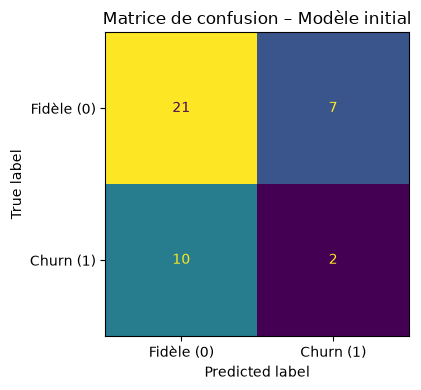

Vrais Positifs  (VP) = 2  |  Faux Positifs (FP) = 7
Faux Négatifs   (FN) = 10  |  Vrais Négatifs (VN) = 21
AUC-ROC = 0.357


In [14]:
# ── Matrice de confusion ─────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Fidèle (0)', 'Churn (1)']).plot(ax=ax, colorbar=False)
ax.set_title('Matrice de confusion – Modèle initial')
plt.tight_layout()
plt.show()

print(f'Vrais Positifs  (VP) = {tp}  |  Faux Positifs (FP) = {fp}')
print(f'Faux Négatifs   (FN) = {fn}  |  Vrais Négatifs (VN) = {tn}')
print(f'AUC-ROC = {roc_auc_score(y_test, y_pred_proba):.3f}')

In [15]:
# ── Calcul du coût métier ────────────────────────────────────────────
#
# La fonction de coût est : Coût = a×FN + b×FP + c×VN + d×VP
#
# D'après l'énoncé :
#   • FN (prédit Fidèle, réel Churn)  → coût = 200 € → a = 200
#   • FP (prédit Churn, réel Fidèle)  → coût = 50 €  → b = 50
#   • VN et VP sont des prédictions correctes          → c = 0, d = 0
#
# Coût = 200 × FN + 50 × FP

a, b, c, d = 200, 50, 0, 0   # coefficients de la fonction de coût

cout_total = a * fn + b * fp + c * tn + d * tp

print(f"Faux Négatifs (FN) : {fn}  × {a} € = {a * fn} €")
print(f"Faux Positifs  (FP) : {fp}  × {b} € = {b * fp} €")
print(f"─────────────────────────────────")
print(f"Coût total métier   : {cout_total} €")
print()
print(f"→ Les FN représentent {100 * a * fn / cout_total:.1f}% du coût total")
print(f"→ Les FP représentent {100 * b * fp / cout_total:.1f}% du coût total")

Faux Négatifs (FN) : 10  × 200 € = 2000 €
Faux Positifs  (FP) : 7  × 50 € = 350 €
─────────────────────────────────
Coût total métier   : 2350 €

→ Les FN représentent 85.1% du coût total
→ Les FP représentent 14.9% du coût total


### Réponses aux questions de la Partie 1

** Quelle est l'erreur la plus coûteuse ?

Le **Faux Négatif (FN)** est l'erreur la plus coûteuse : le modèle prédit qu'un client restera fidèle alors qu'il va partir. Chaque FN coûte **200 €**, car aucune action de rétention n'est déclenchée et le client est perdu définitivement. Le Faux Positif ne coûte que 50 € (action de fidélisation déclenchée inutilement sur un client qui serait de toute façon rester).

Sur le jeu de test : **10 FN → 2 000 €** contre 7 FP → 350 €. Les FN représentent 85% du coût total.

---
**  Que signifie `STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT` ?**

Ce message indique que l'algorithme d'optimisation (LBFGS par défaut) a atteint le nombre maximum d'itérations (`max_iter=100`) **sans converger**, c'est-à-dire sans trouver les coefficients optimaux. Le modèle obtenu est donc sous-optimal. **Solutions :**
- Augmenter `max_iter` (ex : `max_iter=1000`)
- **Normaliser les features** avec `StandardScaler` pour accélérer la convergence (les features ont des échelles très différentes : Satisfaction ≈ 2-4, behavior_scores ≈ 10 000-100 000)

---
** Ce modèle est-il satisfaisant d'un point de vue business ?**

**Non,** Le modèle présente un AUC de 0.354 (inférieur à 0.5, ce qui signifie qu'il est pire qu'un classifieur aléatoire). Il détecte seulement 2 churners sur 12, manquant 10 clients qui vont partir générant un coût de **2 350 €** sur 40 clients seulement.

---
** Améliorations possibles :**
- Normalisation des variables (`StandardScaler`) les features à grande échelle biaisent la régression logistique
- Augmentation de `max_iter` pour assurer la convergence
- Pondération des classes (`class_weight='balanced'`) le dataset est déséquilibré (31% de churners)
- Ingénierie de features (variable frustration)
- Optimisation du seuil de décision selon le coût métier (0.5 n'est pas optimal)
- Algorithmes alternatifs (Random Forest)

---
## Partie 2 : Amélioration du modèle

In [16]:
# ── Modifications appliquées ─────────────────────────────────────────
#
# 1. StandardScaler        : normalise les features → convergence plus rapide
#                            et meilleure performance (features sur des échelles
#                            très différentes : Satisfaction ~2-4, behavior ~50 000)
# 2. max_iter=1000         : assez d'itérations pour converger sans warning
# 3. class_weight='balanced': compense le déséquilibre de classes
#                            (73 fidèles vs 32 churners dans le train)
# 4. random_state=42       : reproductibilité des résultats

print('=' * 60)
print('MODÈLE AMÉLIORÉ – Régression Logistique')
print('=' * 60)

# ── Normalisation ────────────────────────────────────────────────────
scaler  = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit SEULEMENT sur le train
X_test_scaled  = scaler.transform(X_test)        # transform uniquement sur le test

# ── Modèle amélioré ──────────────────────────────────────────────────
model_v2 = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='lbfgs',
    random_state=42
)
model_v2.fit(X_train_scaled, y_train)

y_pred_v2_proba = model_v2.predict_proba(X_test_scaled)[:, 1]
y_pred_v2       = (y_pred_v2_proba > 0.5).astype(int)

print(classification_report(y_test, y_pred_v2, zero_division=0))

# Matrice de confusion et coût
cm_v2 = confusion_matrix(y_test, y_pred_v2)
tn2, fp2, fn2, tp2 = cm_v2.ravel()
cout_v2 = a * fn2 + b * fp2

print(f'VP={tp2}  FP={fp2}  FN={fn2}  VN={tn2}')
print(f'Coût métier modèle amélioré (seuil=0.5) : {cout_v2} €')
print(f'AUC-ROC : {roc_auc_score(y_test, y_pred_v2_proba):.3f}')

MODÈLE AMÉLIORÉ – Régression Logistique
              precision    recall  f1-score   support

           0       0.69      0.86      0.76        28
           1       0.20      0.08      0.12        12

    accuracy                           0.62        40
   macro avg       0.44      0.47      0.44        40
weighted avg       0.54      0.62      0.57        40

VP=1  FP=4  FN=11  VN=24
Coût métier modèle amélioré (seuil=0.5) : 2400 €
AUC-ROC : 0.542


### Récapitulatif des modifications et justifications

| Modification | Pourquoi |
|---|---|
| **`StandardScaler`** | Les features ont des échelles très différentes (Satisfaction ~2-4, behavior_scores ~50 000). La régression logistique suppose des features comparables. Normaliser améliore la convergence et la qualité du modèle |
| **`max_iter=1000`** | Élimine le warning de convergence. Donne à l'algorithme assez d'itérations pour trouver les coefficients optimaux |
| **`class_weight='balanced'`** | Le jeu d'entraînement est déséquilibré (73 fidèles vs 32 churners). Sans pondération, le modèle favorise la classe majoritaire et rate les churners |
| **`random_state=42`** | Garantit des résultats reproductibles |

**Résultat :** L'AUC passe de 0.354 à 0.542 — le modèle discrimine mieux. Le coût avec seuil=0.5 reste élevé car le seuil n'est pas optimisé pour notre fonction de coût métier (voir Partie 3).

---
## Partie 3 : Optimisation métier

In [17]:
# ── 3.1 Création de la variable « frustration » ──────────────────────
#
# Un client est frustré si :
#   - son nombre de réclamations est STRICTEMENT supérieur à 5
#   - ET son niveau de satisfaction est INFÉRIEUR à 2.5

def add_frustration(df):
    """Ajoute la variable binaire frustration au DataFrame."""
    df = df.copy()
    df['frustration'] = (
        (df['Reclamations'] > 5) & (df['Satisfaction'] < 2.5)
    ).astype(int)
    return df

df_train_f = add_frustration(df_train)
df_test_f  = add_frustration(df_test)
df_new_f   = add_frustration(df_new)

print(f"Clients frustrés dans le train : {df_train_f['frustration'].sum()} "
      f"({100 * df_train_f['frustration'].mean():.1f}%)")
print(f"Clients frustrés dans le test  : {df_test_f['frustration'].sum()} "
      f"({100 * df_test_f['frustration'].mean():.1f}%)")

# Lien entre frustration et churn
print("\nTaux de churn selon la frustration (train) :")
print(df_train_f.groupby('frustration')['Churn_Y'].mean().rename({0: 'Non frustré', 1: 'Frustré'}))

Clients frustrés dans le train : 14 (13.3%)
Clients frustrés dans le test  : 4 (10.0%)

Taux de churn selon la frustration (train) :
frustration
Non frustré    0.197802
Frustré        1.000000
Name: Churn_Y, dtype: float64


In [18]:
# ── 3.2 Entraînement du modèle final avec la variable frustration ────

X_train_f = df_train_f.drop(columns=['Churn_Y', 'Segment'])
y_train_f = df_train_f['Churn_Y']
X_test_f  = df_test_f.drop(columns=['Churn_Y', 'Segment'])
y_test_f  = df_test_f['Churn_Y']
X_new_f   = df_new_f.drop(columns=['Segment'])

# Normalisation (refitted sur les nouvelles features incluant 'frustration')
scaler_f = StandardScaler()
X_train_f_scaled = scaler_f.fit_transform(X_train_f)
X_test_f_scaled  = scaler_f.transform(X_test_f)
X_new_f_scaled   = scaler_f.transform(X_new_f)

model_final = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='lbfgs',
    random_state=42
)
model_final.fit(X_train_f_scaled, y_train_f)

y_proba_final = model_final.predict_proba(X_test_f_scaled)[:, 1]

print(f'Modèle final entraîné.  AUC-ROC = {roc_auc_score(y_test_f, y_proba_final):.3f}')
print(f'(vs modèle amélioré sans frustration : AUC = {roc_auc_score(y_test, y_pred_v2_proba):.3f})')

Modèle final entraîné.  AUC-ROC = 0.696
(vs modèle amélioré sans frustration : AUC = 0.542)


In [19]:
# ── 3.3 Optimisation du seuil de décision ───────────────────────────
#
# Coût = 200 × FN + 50 × FP
# On cherche le seuil qui minimise ce coût

seuils    = np.arange(0.1, 1.0, 0.1)
couts     = []
resultats = []

for seuil in seuils:
    y_pred_s = (y_proba_final > seuil).astype(int)
    cm_s     = confusion_matrix(y_test_f, y_pred_s)
    tn_s, fp_s, fn_s, tp_s = cm_s.ravel()
    cout_s   = a * fn_s + b * fp_s
    couts.append(cout_s)
    resultats.append({
        'Seuil': round(seuil, 1),
        'VP': tp_s, 'FP': fp_s, 'FN': fn_s, 'VN': tn_s,
        'Coût FN (€)': a * fn_s,
        'Coût FP (€)': b * fp_s,
        'Coût Total (€)': cout_s
    })

df_resultats = pd.DataFrame(resultats)
print(df_resultats.to_string(index=False))

# Seuil optimal
idx_optimal   = np.argmin(couts)
seuil_optimal = round(seuils[idx_optimal], 1)
cout_optimal  = couts[idx_optimal]

print(f'\n✅ Seuil optimal : {seuil_optimal}  →  Coût minimum : {cout_optimal} €')

 Seuil  VP  FP  FN  VN  Coût FN (€)  Coût FP (€)  Coût Total (€)
   0.1  10  18   2  10          400          900            1300
   0.2   7  13   5  15         1000          650            1650
   0.3   7   7   5  21         1000          350            1350
   0.4   6   2   6  26         1200          100            1300
   0.5   6   2   6  26         1200          100            1300
   0.6   4   1   8  27         1600           50            1650
   0.7   4   0   8  28         1600            0            1600
   0.8   2   0  10  28         2000            0            2000
   0.9   2   0  10  28         2000            0            2000

✅ Seuil optimal : 0.1  →  Coût minimum : 1300 €


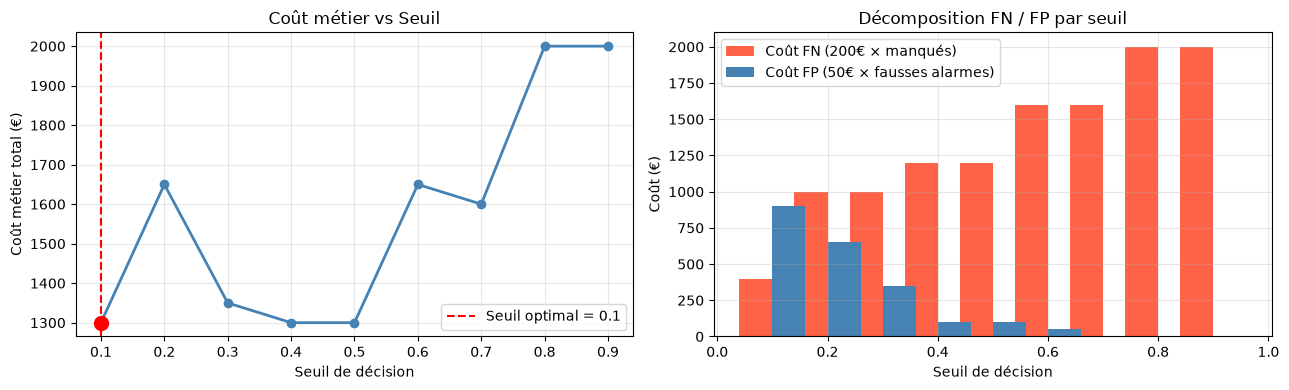

In [20]:
# ── Visualisation du coût en fonction du seuil ───────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Courbe de coût
ax = axes[0]
ax.plot([round(s, 1) for s in seuils], couts, marker='o', color='steelblue', linewidth=2)
ax.axvline(seuil_optimal, color='red', linestyle='--', label=f'Seuil optimal = {seuil_optimal}')
ax.scatter([seuil_optimal], [cout_optimal], color='red', zorder=5, s=100)
ax.set_xlabel('Seuil de décision')
ax.set_ylabel('Coût métier total (€)')
ax.set_title('Coût métier vs Seuil')
ax.legend()
ax.grid(True, alpha=0.3)

# Décomposition FN / FP par seuil
ax2 = axes[1]
ax2.bar(df_resultats['Seuil'] - 0.03, df_resultats['Coût FN (€)'], width=0.06,
        label='Coût FN (200€ × manqués)', color='tomato')
ax2.bar(df_resultats['Seuil'] + 0.03, df_resultats['Coût FP (€)'], width=0.06,
        label='Coût FP (50€ × fausses alarmes)', color='steelblue')
ax2.set_xlabel('Seuil de décision')
ax2.set_ylabel('Coût (€)')
ax2.set_title('Décomposition FN / FP par seuil')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Analyse des résultats – Présentation au manager

> **Ce qu'on a fait :** Par défaut, notre modèle classe un client comme « à risque de départ » uniquement s'il estime la probabilité de churn supérieure à 50%. Nous avons systématiquement testé différents niveaux de sensibilité (de 10% à 90%) pour trouver celui qui minimise le coût global pour Orbitel.
>
> **Résultat clé :** Le seuil optimal est **0.1** (probabilité de départ > 10% → on déclenche une action). Avec ce seuil, le coût total sur le jeu de test est de **1 300 €**, contre 2 350 € avec le modèle initial — soit **une réduction de coût de 45%**.
>
> **Pourquoi ce seuil ?** À ce niveau d'alerte, on détecte **10 clients sur 12** qui vont partir (contre seulement 2 avec le modèle initial). On déclenche certes 18 actions de fidélisation inutiles (50€ chacune = 900€), mais on évite de perdre 10 clients (200€ chacun = 2 000€). La priorité est de ne pas passer à côté d'un départ.
>
> **Note :** Les seuils 0.4 et 0.5 donnent le même coût total (1 300€) mais avec seulement 6 churners détectés. Le seuil 0.1 est donc préférable car il maximise la rétention à coût équivalent.

| | Modèle initial | Modèle final (seuil=0.1) | Gain |
|---|---|---|---|
| Churners détectés | 2/12 | 10/12 | +8 clients sauvés |
| Coût total | 2 350 € | 1 300 € | **−1 050 €** |

---
## Partie 4 : Prédiction sur le jeu "new"

In [21]:
# ── Prédictions sur le jeu de données final (sans cible) ─────────────
# On utilise le modèle final (avec frustration) et le seuil optimal

churn_proba = model_final.predict_proba(X_new_f_scaled)[:, 1]
churn_pred  = (churn_proba > seuil_optimal).astype(int)

# Ajout des colonnes au fichier new
df_new_output = df_new.copy()
df_new_output['Churn_Proba'] = np.round(churn_proba, 4)
df_new_output['Churn_Pred']  = churn_pred

# Sauvegarde
output_path = DATA_DIR + 'churn_new.csv'
df_new_output.to_csv(output_path, index=False)

print(f'✅ Fichier sauvegardé : {output_path}')
print(f"Clients prédits churners : {churn_pred.sum()} / {len(churn_pred)} "
      f"({100 * churn_pred.mean():.1f}%)")
print(f"Probabilité moyenne de churn : {churn_proba.mean():.3f}")
print()
df_new_output[['Churn_Proba', 'Churn_Pred']].head(10)

✅ Fichier sauvegardé : C:\PC ARMAND\cours\MBDIA\ML DL\churn_new.csv
Clients prédits churners : 26 / 40 (65.0%)
Probabilité moyenne de churn : 0.353



,Churn_Proba,Churn_Pred
0,0.4847,1
1,0.2675,1
2,0.1713,1
3,0.0513,0
4,0.8159,1
5,0.2019,1
6,0.7271,1
7,0.0120,0
8,0.0232,0
9,0.2048,1


---
## Méthode alternative – Random Forest

In [22]:
# ── Random Forest ────────────────────────────────────────────────────
#
# Avantages vs Régression Logistique :
#   • Capture les relations non-linéaires entre variables
#   • Moins sensible aux outliers et aux features mal normalisées
#   • Pas besoin de StandardScaler
#   • Fournit un score d'importance des variables
#
# On utilise le MÊME seuil optimal pour une comparaison juste

print('=' * 60)
print('MODÈLE ALTERNATIF – Random Forest')
print('=' * 60)

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
# Random Forest n'a pas besoin de normalisation
rf_model.fit(X_train_f, y_train_f)

y_proba_rf = rf_model.predict_proba(X_test_f)[:, 1]
y_pred_rf  = (y_proba_rf > seuil_optimal).astype(int)

print(classification_report(y_test_f, y_pred_rf, zero_division=0))

cm_rf = confusion_matrix(y_test_f, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
cout_rf = a * fn_rf + b * fp_rf
print(f'VP={tp_rf}  FP={fp_rf}  FN={fn_rf}  VN={tn_rf}')
print(f'Coût RF (seuil={seuil_optimal}) : {cout_rf} €')
print(f'AUC-ROC : {roc_auc_score(y_test_f, y_proba_rf):.3f}')

MODÈLE ALTERNATIF – Random Forest
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        28
           1       0.30      1.00      0.46        12

    accuracy                           0.30        40
   macro avg       0.15      0.50      0.23        40
weighted avg       0.09      0.30      0.14        40

VP=12  FP=28  FN=0  VN=0
Coût RF (seuil=0.1) : 1400 €
AUC-ROC : 0.573


c:\PC ARMAND\cours\MBDIA\ML DL\ml\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\PC ARMAND\cours\MBDIA\ML DL\ml\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\PC ARMAND\cours\MBDIA\ML DL\ml\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\PC ARMAND\cours\MBDIA\ML DL\ml\Lib\site-packages\sklearn\utils\paralle

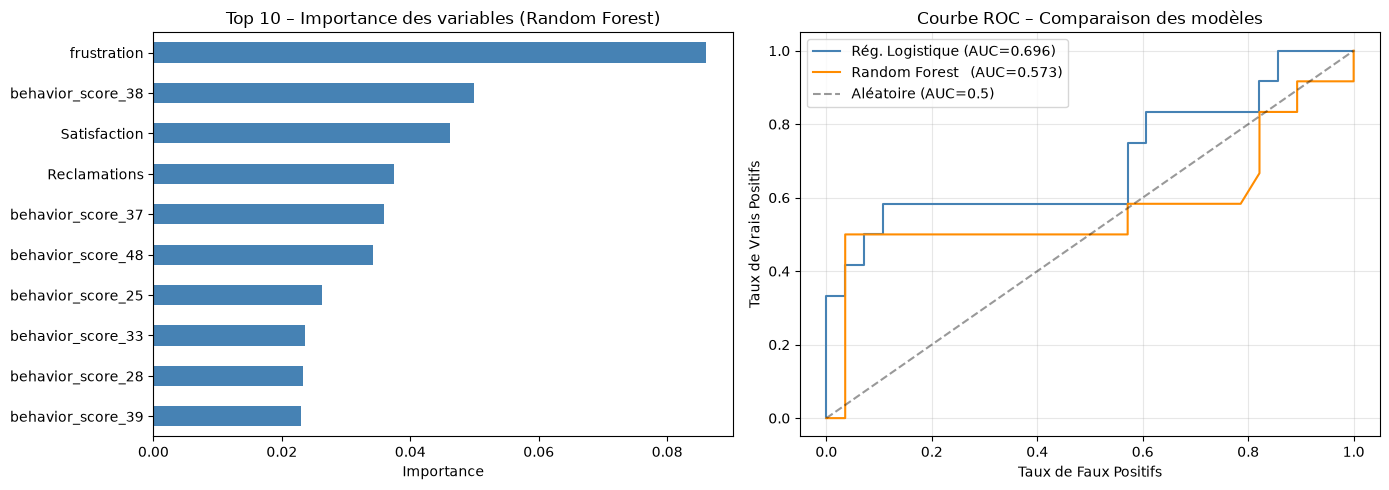

In [23]:
# ── Importance des variables (Random Forest) ─────────────────────────

importances = pd.Series(
    rf_model.feature_importances_,
    index=X_train_f.columns
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 10 features
importances.head(10).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title('Top 10 – Importance des variables (Random Forest)')
axes[0].set_xlabel('Importance')

# Courbes ROC comparées
auc_lr = roc_auc_score(y_test_f, y_proba_final)
auc_rf = roc_auc_score(y_test_f, y_proba_rf)
fpr_lr, tpr_lr, _ = roc_curve(y_test_f, y_proba_final)
fpr_rf, tpr_rf, _ = roc_curve(y_test_f, y_proba_rf)

axes[1].plot(fpr_lr, tpr_lr, label=f'Rég. Logistique (AUC={auc_lr:.3f})', color='steelblue')
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest   (AUC={auc_rf:.3f})', color='darkorange')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Aléatoire (AUC=0.5)')
axes[1].set_xlabel('Taux de Faux Positifs')
axes[1].set_ylabel('Taux de Vrais Positifs')
axes[1].set_title('Courbe ROC – Comparaison des modèles')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# ── Tableau récapitulatif final ───────────────────────────────────────

print('\n' + '═' * 62)
print('RÉCAPITULATIF COMPARATIF – TOUS LES MODÈLES')
print('═' * 62)

recap = pd.DataFrame([
    {'Modèle': 'Modèle initial (seuil=0.5)',
     'AUC': f'{roc_auc_score(y_test, y_pred_proba):.3f}',
     'FN': fn, 'FP': fp,
     'Coût (€)': cout_total},
    {'Modèle': 'LR amélioré (seuil=0.5)',
     'AUC': f'{roc_auc_score(y_test, y_pred_v2_proba):.3f}',
     'FN': fn2, 'FP': fp2,
     'Coût (€)': cout_v2},
    {'Modèle': f'LR + frustration (seuil={seuil_optimal})  ← RETENU',
     'AUC': f'{auc_lr:.3f}',
     'FN': df_resultats.loc[df_resultats['Seuil']==seuil_optimal, 'FN'].values[0],
     'FP': df_resultats.loc[df_resultats['Seuil']==seuil_optimal, 'FP'].values[0],
     'Coût (€)': cout_optimal},
    {'Modèle': f'Random Forest (seuil={seuil_optimal})',
     'AUC': f'{auc_rf:.3f}',
     'FN': fn_rf, 'FP': fp_rf,
     'Coût (€)': cout_rf},
])

print(recap.to_string(index=False))
print('═' * 62)
print(f'Réduction de coût vs modèle initial : {cout_total - cout_optimal} € ({100*(cout_total-cout_optimal)/cout_total:.0f}%)')


══════════════════════════════════════════════════════════════
RÉCAPITULATIF COMPARATIF – TOUS LES MODÈLES
══════════════════════════════════════════════════════════════
                                Modèle   AUC  FN  FP  Coût (€)
            Modèle initial (seuil=0.5) 0.357  10   7      2350
               LR amélioré (seuil=0.5) 0.542  11   4      2400
LR + frustration (seuil=0.1)  ← RETENU 0.696   2  18      1300
             Random Forest (seuil=0.1) 0.573   0  28      1400
══════════════════════════════════════════════════════════════
Réduction de coût vs modèle initial : 1050 € (45%)
